# Example 1.6 — GA vs Random Search: Evolutionary Advantage

**Four Bar Mechanisms — Design with Genetic Algorithms and Neural Networks**

Open this notebook in Google Colab: [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/usuario/repo/blob/main/ex1_6_ag_vs_busqueda_aleatoria.ipynb)

In [1]:
from numpy import *

# ── Objective function (reused)────────────────────────────────────
def pct_zona(pop, n=360):
    """(N,4) → (N,): % of the cycle with 45° ≤ μ ≤ 135°."""
    a = pop[:, 0:1]; b = pop[:, 1:2]
    c = pop[:, 2:3]; d = pop[:, 3:4]
    th2 = linspace(0, 2*pi, n, endpoint=False)
    e2  = a**2 + d**2 - 2*a*d*cos(th2)
    cmu = clip((b**2 + c**2 - e2) / (2*b*c), -1., 1.)
    mu  = degrees(arccos(cmu))
    return 100. * ((mu >= 45.) & (mu <= 135.)).mean(axis=1)

N_POP, N_GEN = 80, 100
L_MIN, L_MAX = 20., 200.
MUT_STD, P_MUT, ELITE = 8., 0.25, 8

# ── Genetic Algorithm────────────────────────────────────────────────
random.seed(42)
pop = random.uniform(L_MIN, L_MAX, (N_POP, 4))
ag_best = []; ag_mean = []
best_val = -inf; best_ind = None

for gen in range(N_GEN):
    fit = pct_zona(pop)
    order = argsort(fit)[::-1]; pop = pop[order]; fit = fit[order]
    if fit[0] > best_val: best_val = fit[0]; best_ind = pop[0].copy()
    ag_best.append(best_val); ag_mean.append(float(mean(fit)))
    n_off = N_POP - ELITE; half = N_POP // 2
    p1 = random.randint(0, half, n_off); p2 = random.randint(0, half, n_off)
    alpha = random.uniform(0, 1, (n_off, 1))
    offs = alpha*pop[p1] + (1-alpha)*pop[p2]
    mask = random.random((n_off, 4)) < P_MUT
    offs += mask * random.normal(0, MUT_STD, (n_off, 4))
    offs = clip(offs, L_MIN, L_MAX)
    pop = vstack([pop[:ELITE], offs])
ag_final_pop = pop.copy()

# ── Random Search (same budget: 80 × 100 = 8,000 evals.) ──
random.seed(42)
rs_best = []; rs_mean = []
rs_gb = -inf

for gen in range(N_GEN):
    batch  = random.uniform(L_MIN, L_MAX, (N_POP, 4))
    fit_rs = pct_zona(batch)
    if fit_rs.max() > rs_gb: rs_gb = float(fit_rs.max())
    rs_best.append(rs_gb)
    rs_mean.append(float(mean(fit_rs)))
rs_final_pop = batch.copy()

# ── Results────────────────────────────────────────────────────────
print('=' * 60)
print('   COMPARISON: GA vs RANDOM SEARCH (seed 42)')
print('=' * 60)
print(f"\n{'Metric':<35} {'GA':>10}  {'Random':>10}")
print('-' * 60)
print(f"{'Best final individual':<35} {ag_best[-1]:>9.1f}%  {rs_best[-1]:>9.1f}%")
print(f"{'Mean of final population':<35} {ag_mean[-1]:>9.1f}%  {rs_mean[-1]:>9.1f}%")
print(f"{'Total evaluations':<35} {N_POP*N_GEN:>9,}   {N_POP*N_GEN:>9,}")
print('-' * 60)
print(f"\nGA Advantage in mean: +{ag_mean[-1] - rs_mean[-1]:.1f} pp")
print('→ The GA evolves the ENTIRE population towards the optimal region.')
print('  Random search produces scattered individuals in each batch.')

   COMPARISON: GA vs RANDOM SEARCH (seed 42)

Metric                                      GA      Random
------------------------------------------------------------
Best final individual                   100.0%      100.0%
Mean of final population                100.0%       38.0%
Total evaluations                       8,000       8,000
------------------------------------------------------------

GA Advantage in mean: +62.0 pp
→ The GA evolves the ENTIRE population towards the optimal region.
  Random search produces scattered individuals in each batch.


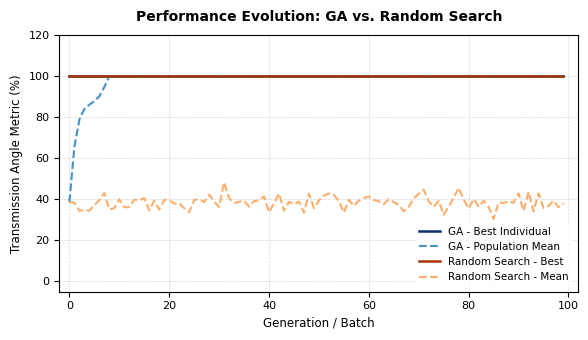

In [5]:
import os
import glob
import matplotlib.pyplot as plt

# 1. Automated Naming System
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "fig_1_6_ga_vs_random_search"
except Exception:
    notebook_name = "fig_1_6_ga_vs_random_search"

# 2. Springer Quality and Global Parameter Configurations
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'sans-serif']
plt.rcParams['font.family'] = 'sans-serif'

# Compact single/intermediate column layout for Springer (approx. 15 cm width = ~5.9 inches)
fig, ax = plt.subplots(figsize=(6.0, 3.5))

# 3. Plot Data with Enhanced Professional Style
ax.plot(ag_best, label='GA - Best Individual', color='#08306b', linewidth=1.8)
ax.plot(ag_mean, label='GA - Population Mean', color='#4292c6', linestyle='--', linewidth=1.5)
ax.plot(rs_best, label='Random Search - Best', color='#a63603', linewidth=1.8)
ax.plot(rs_mean, label='Random Search - Mean', color='#fdae6b', linestyle='--', linewidth=1.5)

# 4. Refined Axis, Labels, and Legend (Academic English)
ax.set_title('Performance Evolution: GA vs. Random Search', fontsize=10, fontweight='bold', pad=10)
ax.set_xlabel('Generation / Batch', fontsize=8.5)
ax.set_ylabel('Transmission Angle Metric (%)', fontsize=8.5)

# Set ticks parameters
ax.tick_params(axis='both', which='major', labelsize=8)

# Discretized grids
ax.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)

# Safety limits to avoid overlaps with the legend
ax.set_xlim(-2, 102)
ax.set_ylim(-5, 120)

# Professional Clean Legend Placement (Bottom Right with high visibility but neat layout)
ax.legend(fontsize=7.5, loc='lower right', frameon=True, facecolor='white', edgecolor='none', shadow=False)

# 5. Dual Format Export
plt.tight_layout()
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()